# Runlet 退款审核故障实验
Runlet 基线为 82c7a7f，实验实现为 fc35b3d。使用 Go 1.26.5、MySQL 8.0.46 和 WSL 2。所有订单、模型响应和网关账本均为本地合成实验。业务正确性由场景断言和独立账本共同判定。

下列采集命令在完整 Runlet 的 fc35b3d 工作区运行。当前仓库提供核心源码选段和去标识的实测数据，可直接执行分析单元复算结果。设定 MYSQL_DSN 指向专用测试库。开销与故障执行器如并行运行应各用一个测试库。把输出文件放到本 Notebook 目录。早期共用数据库导致激活构建互相覆盖，正式对照改用独立数据库。其日志保留用于排查，以下统计仅使用正式结果。

```bash
go run ./examples/refund-review/scenarios -repeat 5 -only direct-refund,approved,rejected,approval-timeout,kill-while-waiting,kill-after-refund,dropped-response,reexecute-after-refund,reexecute-dropped-response >comparison.log 2>&1
go run ./examples/refund-review/scenarios -measure >journal.csv 2>journal.log
python3 examples/refund-review/scenarios/memory_baseline.py >memory.jsonl
```


In [1]:
from collections import defaultdict
from pathlib import Path
from statistics import median, quantiles
import csv
import json
import re

log = Path("comparison.log").read_text(encoding="utf-8")
records = defaultdict(list)
for status, name, value, unit in re.findall(
        r"--- (PASS|FAIL) ([\w-]+) \(([\d.]+)(ms|s)\)", log):
    records[name].append((status, float(value)/(1000 if unit=="ms" else 1)))
for name, rows in records.items():
    times = [t for status, t in rows if status=="PASS"]
    print(f"{name:26} {len(times)}/{len(rows)} passed; median {median(times):.3f} s")


reexecute-after-refund     5/5 passed; median 31.884 s
reexecute-dropped-response 5/5 passed; median 32.037 s
direct-refund              5/5 passed; median 1.529 s
approved                   5/5 passed; median 2.719 s
rejected                   5/5 passed; median 2.656 s
kill-while-waiting         5/5 passed; median 1.859 s
kill-after-refund          5/5 passed; median 33.087 s
dropped-response           5/5 passed; median 3.689 s
approval-timeout           5/5 passed; median 4.581 s


审批恢复场景在无 Worker 时提交回答，启动后核对一次账本落账与各调用步骤 attempt。仅内存基线验证同一个交互契约，模型和工具调用数是合成轨迹。

In [2]:
memory = [json.loads(line) for line in Path("memory.jsonl").read_text().splitlines()]
assert all(not row["offline_answer_saved"] and row["approval_prompts"] == 2 for row in memory)
print(f"{len(memory)} runs: approval could not be delivered offline; restart required a new approval.")


5 runs: approval could not be delivered offline; restart required a new approval.


对照的通过定义包含账本断言。自动重执行样本出现两笔是预设检验条件成立，业务上属于重复退款。暂停核验样本按退款单号核实账本并补录回执。

In [3]:
print("duplicate ledger observations:", log.count("E3 duplicate ledger_count=2"))
first = log.split("=== kill-after-refund:")[1].split("--- PASS")[0]
for line in first.splitlines():
    event = next((label for key, label in [
        ("DEMO_CRASH", "Worker exited after gateway callback"),
        ("is waiting OUTCOME_UNKNOWN", "Waiting for verification"),
        ("admin recorded result", "Receipt recorded"),
        ("is completed", "Completed"),
    ] if key in line), None)
    if event:
        timestamp = re.search(r"\d\d:\d\d:\d\d\.\d+", line).group()
        print(timestamp, event)


duplicate ledger observations: 10
21:41:18.713636 Worker exited after gateway callback
21:41:49.119092 Waiting for verification
21:41:49.156852 Receipt recorded
21:41:50.318876 Completed


开销量测使用固定的小整数输入和结果。每个长度有 15 个样本。恢复用持久等待的回答触发，量测从 Worker 任务入口开始，排除获取租约与人为等待。

60 measured replays; 0 completed prefix callbacks repeated.
(a) First durable execution [331.902, 1346.9273, 2718.9115, 5473.8499]
(b) Replay after durable wait [29.9554, 82.0531, 162.4047, 333.9446]
Direct execution median (μs): [0.281, 0.27, 0.375, 0.385]


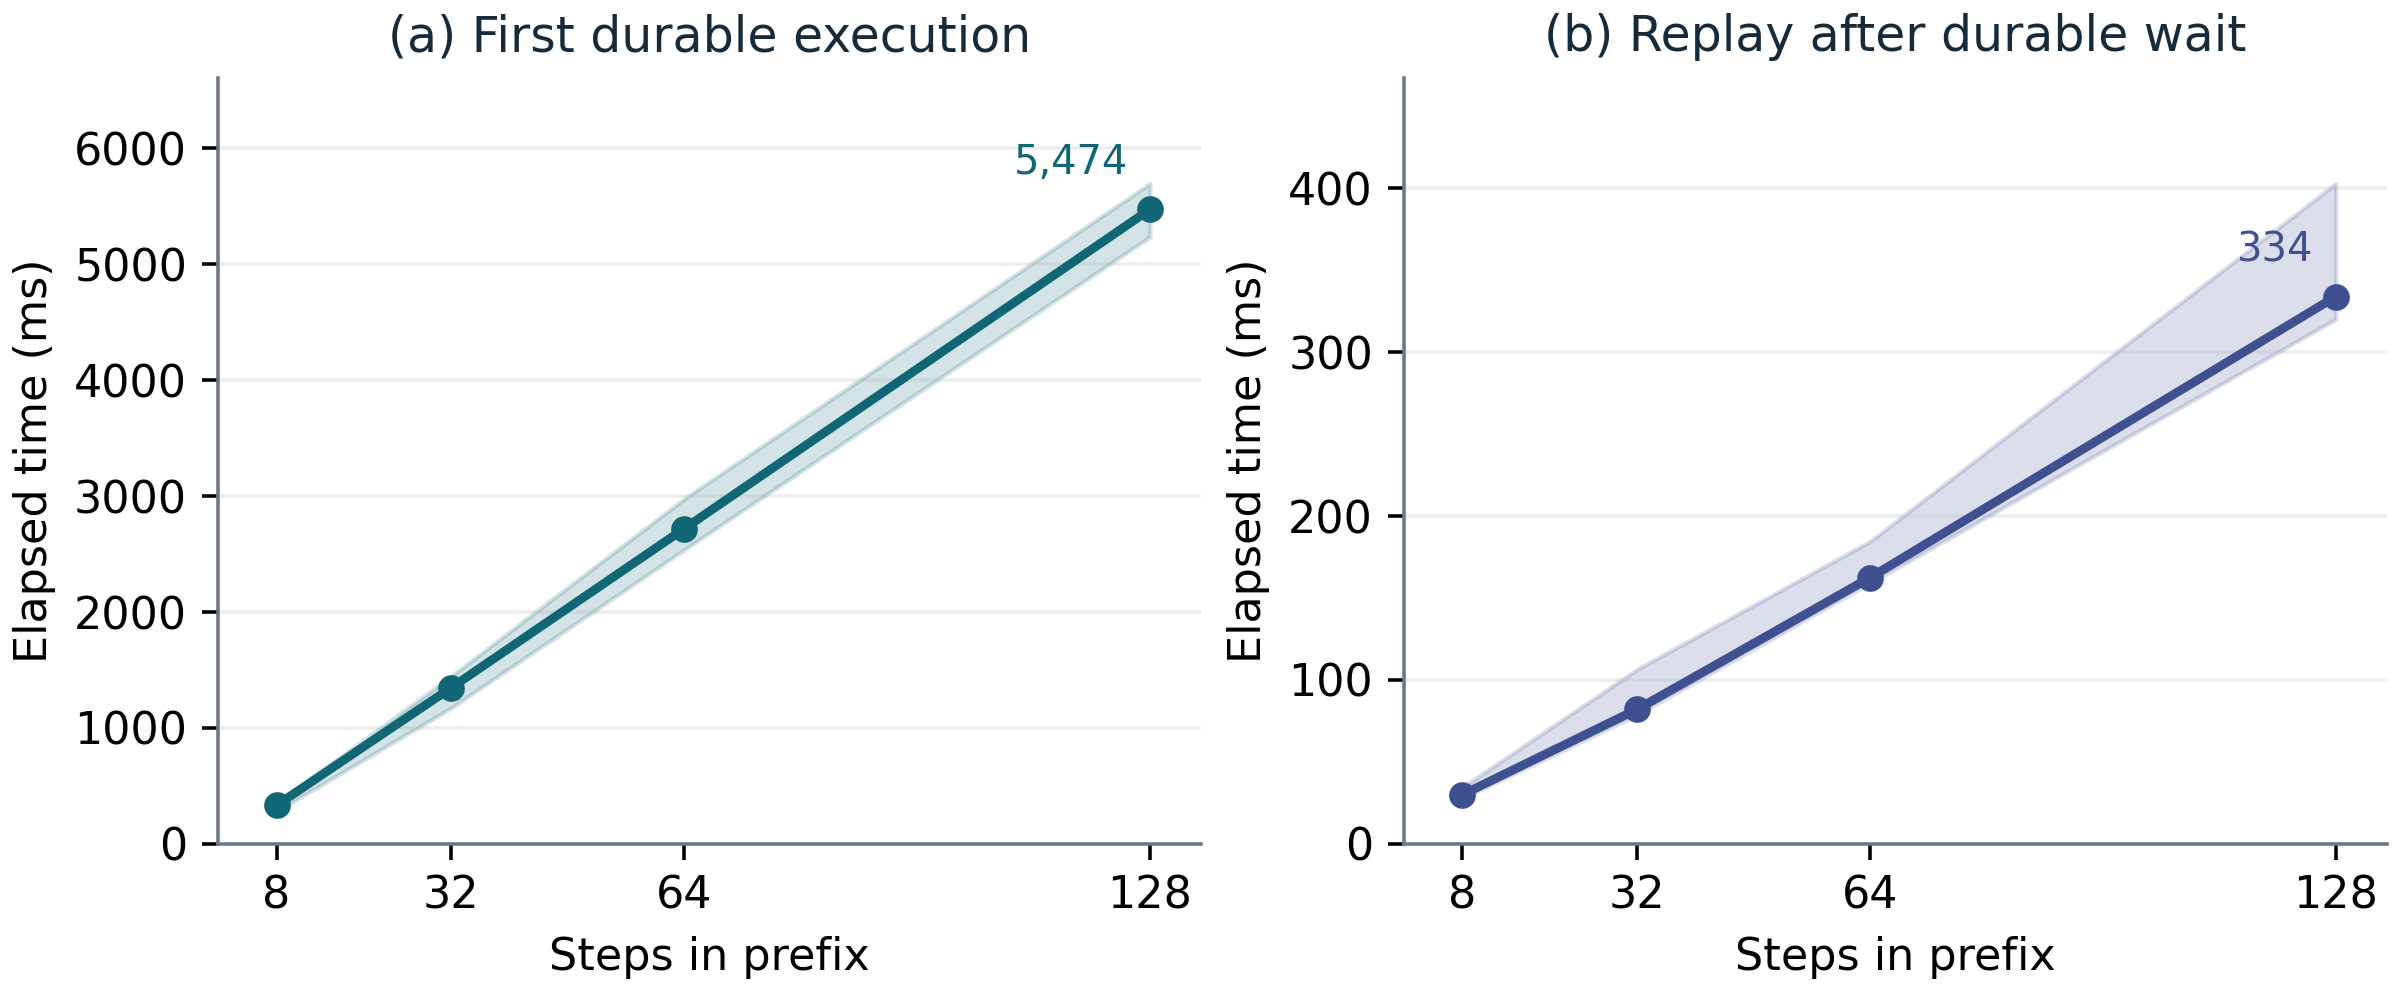

In [4]:
import matplotlib.pyplot as plt

rows = list(csv.DictReader(Path("journal.csv").open(encoding="utf-8")))
steps = sorted({int(row["steps"]) for row in rows})
assert all(int(row["replay_callbacks"]) == 0 for row in rows)
print(f"{len(rows)} measured replays; 0 completed prefix callbacks repeated.")
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.1), layout="constrained")
for ax, key, title, color in [
    (axes[0], "normal_ns", "(a) First durable execution", "#116676"),
    (axes[1], "replay_ns", "(b) Replay after durable wait", "#3F5091"),
]:
    groups = [[int(row[key])/1e6 for row in rows if int(row["steps"])==n] for n in steps]
    medians = [median(values) for values in groups]
    q1, _, q3 = zip(*(quantiles(values, n=4, method="inclusive") for values in groups))
    ax.fill_between(steps, q1, q3, alpha=.18, color=color)
    ax.plot(steps, medians, "o-", linewidth=2, markersize=5, color=color)
    ax.set(title=title, xlabel="Steps in prefix", ylabel="Elapsed time (ms)", xticks=steps,
           xlim=(0, 135), ylim=(0, max(q3)*1.16))
    ax.grid(axis="y", alpha=.22)
    ax.annotate(f"{medians[-1]:,.0f}", (steps[-1], medians[-1]), xytext=(-5, 8),
                textcoords="offset points", ha="right", color=color, fontsize=9)
    print(title, [round(x, 4) for x in medians])
print("Direct execution median (μs):", [
    median(int(row["direct_ns"])/1000 for row in rows if int(row["steps"])==n) for n in steps
])
plt.show()


正常路径包含步骤记录的 RPC 与 MySQL 提交。重放路径仍需逐步读取历史，但不重复调用已提交的回调。结论局限于单机、小载荷、有限长度和这两类受控故障。